# 📚 Books Rating and Sales — Exploratory Data Analysis (EDA)

## 1. Project Introduction
This project explores a books dataset to understand patterns in publishing, genres, reader ratings, languages, publishers, and book sales. The analysis uses Python libraries such as **Pandas**, **Matplotlib**, and **Seaborn** to clean, summarize, and visualize the data.

## . Importing Libraries and Loading the Dataset
The notebook uses Pandas for data handling, NumPy for numerical operations, Matplotlib for plotting, and Seaborn for statistical visualizations. The CSV file is loaded into a DataFrame named `df`.

In [ ]:

pip install pandas matplotlib seaborn

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

In [4]:
df = pd.read_csv('Books_Data_Clean.csv')

## Initial Data Inspection
`df.head()` displays the first five records

In [9]:
df.head()

,index,Publishing Year,Book Name,Author,language_code,Author_Rating,Book_average_rating,Book_ratings_count,genre,gross sales,publisher revenue,sale price,sales rank,Publisher,units sold
0,0,1975.0,Beowulf,"Unknown, Seamus Heaney",en-US,Novice,3.42,155903,genre fiction,34160.0,20496.0,4.88,1,HarperCollins Publishers,7000
1,1,1987.0,Batman: Year One,"Frank Miller, David Mazzucchelli, Richmond Lew...",eng,Intermediate,4.23,145267,genre fiction,12437.5,7462.5,1.99,2,HarperCollins Publishers,6250
2,2,2015.0,Go Set a Watchman,Harper Lee,eng,Novice,3.31,138669,genre fiction,47795.0,28677.0,8.69,3,"Amazon Digital Services, Inc.",5500
3,3,2008.0,When You Are Engulfed in Flames,David Sedaris,en-US,Intermediate,4.04,150898,fiction,41250.0,24750.0,7.50,3,Hachette Book Group,5500
4,4,2011.0,Daughter of Smoke & Bone,Laini Taylor,eng,Intermediate,4.04,198283,genre fiction,37952.5,22771.5,7.99,4,Penguin Group (USA) LLC,4750


In [12]:
df.describe()

,index,Publishing Year,Book_average_rating,Book_ratings_count,gross sales,publisher revenue,sale price,sales rank,units sold
count,1009.000000,1009.000000,1009.000000,1009.000000,1009.000000,1009.000000,1009.000000,1009.000000,1009.000000
mean,535.926660,1994.730426,4.012230,94817.793855,1832.644985,841.360638,4.844311,613.314172,9744.482656
std,308.769358,23.204719,0.246492,31473.890412,3947.885096,2279.579848,3.561712,369.628663,15350.021050
min,0.000000,1901.000000,2.970000,27308.000000,104.940000,0.000000,0.990000,1.000000,106.000000
25%,271.000000,1989.000000,3.860000,70701.000000,366.300000,0.000000,1.990000,291.000000,570.000000
50%,535.000000,2003.000000,4.030000,89204.000000,792.000000,273.240000,3.990000,596.000000,3942.000000
75%,802.000000,2010.000000,4.180000,113400.000000,1470.260000,714.756000,6.990000,933.000000,5427.000000
max,1069.000000,2016.000000,4.770000,206792.000000,47795.000000,28677.000000,33.860000,1273.000000,61560.000000


##  Data Cleaning and Preparation
The publishing-year filter keeps records with a year greater than 1900. This removes records outside the selected time range for this analysis.

In [11]:
df = df[df["Publishing Year"]> 1900]

### Checking Missing Values
`df.isna().sum()` counts missing values in each column

In [16]:
df.isna().sum()

index                   0
Publishing Year         0
Book Name               0
Author                  0
language_code          47
Author_Rating           0
Book_average_rating     0
Book_ratings_count      0
genre                   0
gross sales             0
publisher revenue       0
sale price              0
sales rank              0
Publisher               0
units sold              0
dtype: int64

### Removing Rows Without a Book Name
The code drops rows where `Book Name` is missing

In [15]:
df.dropna(subset=["Book Name"], inplace=True)

### Checking Duplicate Records
`df.duplicated().sum()` checks how many complete duplicate rows are present.

In [17]:
df.duplicated().sum()

np.int64(0)

### Counting Unique Values
`df.nunique()` counts distinct values in each column.

In [19]:
df.nunique()

index                  988
Publishing Year        101
Book Name              987
Author                 669
language_code            8
Author_Rating            4
Book_average_rating    133
Book_ratings_count     983
genre                    4
gross sales            774
publisher revenue      570
sale price             143
sales rank             818
Publisher                9
units sold             470
dtype: int64

## Exploratory Data Analysis and Visualizations

### Distribution of Books by Publishing Year
**What the graph shows:** The histogram groups books by publishing year and displays how many records fall within each year range.

 

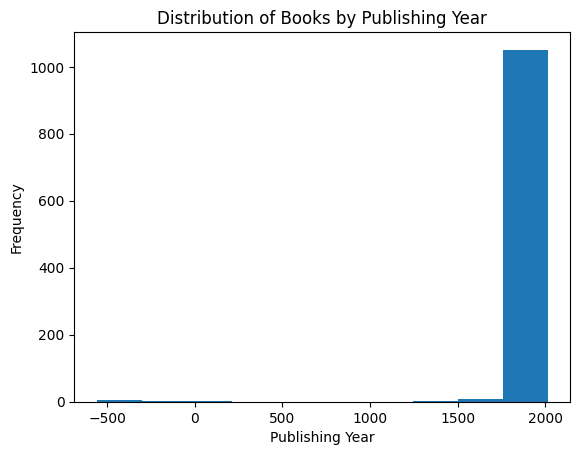

In [22]:
plt.hist(df["Publishing Year"] )
plt.xlabel("Publishing Year")
plt.ylabel("Frequency")
plt.title("Distribution of Books by Publishing Year")
plt.show()

### Distribution of Books by Genre
**What the graph shows:** The bar chart compares the number of books in each genre.

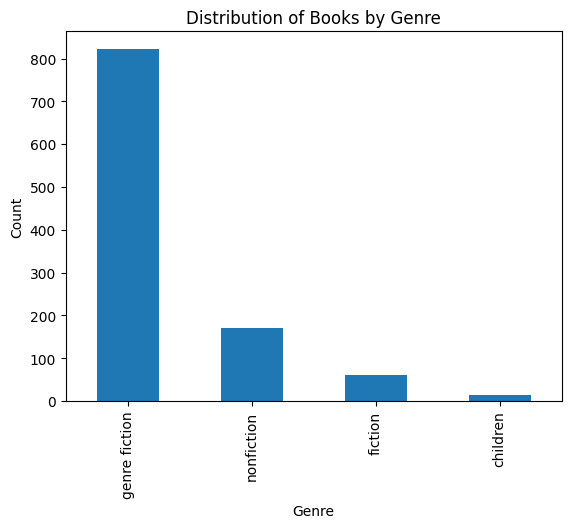

In [23]:
df["genre"].value_counts().plot(kind="bar")
plt.xlabel("Genre")
plt.ylabel("Count")
plt.title("Distribution of Books by Genre")
plt.show()

### Average Book Rating by Author
**What the analysis shows:** The code groups books by author, calculates each author's mean `Book_average_rating`, and sorts the results from highest to lowest.

In [24]:
df.groupby("Author")["Book_average_rating"].mean().sort_values(ascending=False)

Author
Bill Watterson                  4.650
Bill Watterson, G.B. Trudeau    4.610
J.R.R. Tolkien                  4.590
George R.R. Martin              4.560
Sarah J. Maas                   4.526
                                ...  
Audrey Niffenegger              3.230
Herman Koch, Sam Garrett        3.220
P.D. James                      3.210
Stephen Crane                   3.210
Sue Monk Kidd                   3.100
Name: Book_average_rating, Length: 735, dtype: float64

### Book Ratings Count by Genre
**What the graph shows:** The box plot compares the distribution of `Book_ratings_count` across genres. The middle line represents the median, the box represents the middle 50% of observations, and points beyond the whiskers may indicate outliers.

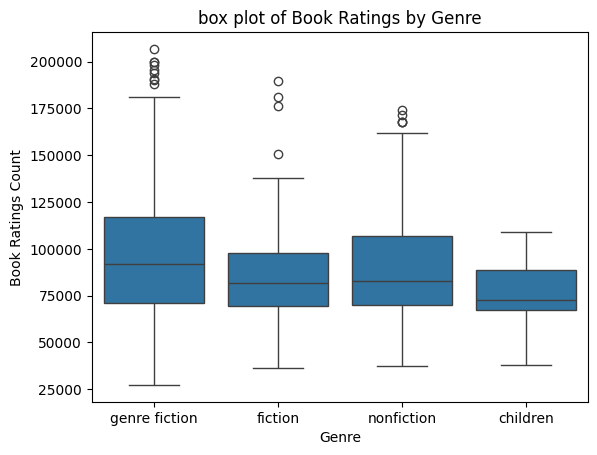

In [25]:
sns.boxplot(x="genre", y="Book_ratings_count", data=df) 
plt.xlabel("Genre")
plt.ylabel("Book Ratings Count")
plt.title("box plot of Book Ratings by Genre")
plt.show()

### Sale Price vs Units Sold
**What the graph shows:** Each point represents a book, with sale price on the x-axis and units sold on the y-axis.

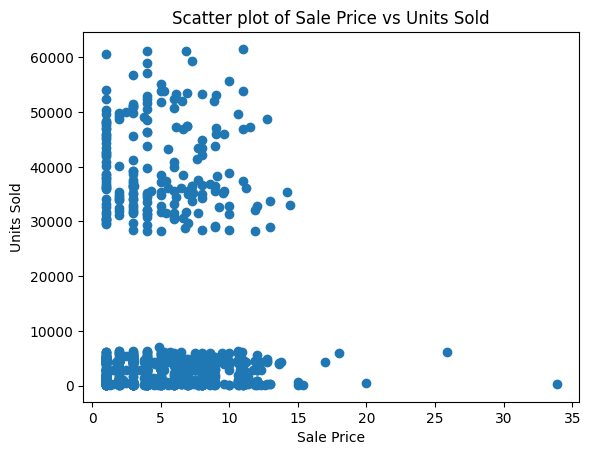

In [26]:
plt.scatter(df["sale price"], df["units sold"])
plt.xlabel("Sale Price")
plt.ylabel("Units Sold")
plt.title("Scatter plot of Sale Price vs Units Sold")
plt.show()

### Preparing Language Counts
The code counts the number of records for each `language_code`. These counts are then used to build the pie chart.

In [27]:
lanuage_counts = df["language_code"].value_counts()

### Distribution of Books by Language
**What the graph shows:** The pie chart displays each language code's share of the records with a non-missing language value.

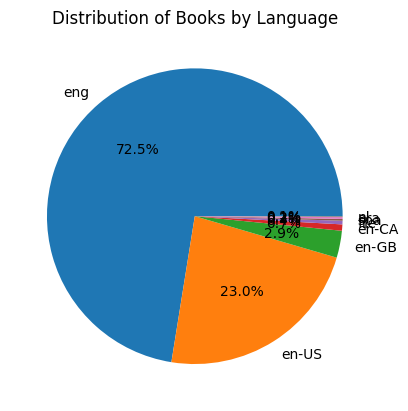

In [28]:
plt.pie(lanuage_counts, labels=lanuage_counts.index, autopct='%1.1f%%')
plt.title("Distribution of Books by Language")
plt.show()

In [29]:
df.columns

Index(['index', 'Publishing Year', 'Book Name', 'Author', 'language_code',
       'Author_Rating', 'Book_average_rating', 'Book_ratings_count', 'genre',
       'gross sales', 'publisher revenue', 'sale price', 'sales rank',
       'Publisher ', 'units sold'],
      dtype='str')

### Average Publisher Revenue by Publisher
**What the analysis shows:** The code groups records by publisher, calculates the mean `publisher revenue` for each publisher, and sorts the averages in descending order.

In [30]:
df.groupby("Publisher ")["publisher revenue"].mean().sort_values(ascending=False)

Publisher 
Hachette Book Group                     2089.007545
Penguin Group (USA) LLC                 1979.791500
HarperCollins Publishers                1809.552930
Random House LLC                        1579.876850
Simon and Schuster Digital Sales Inc     839.077714
Macmillan                                789.176488
HarperCollins Publishing                 707.701500
HarperCollins Christian Publishing       533.917500
Amazon Digital Services,  Inc.           247.073630
Name: publisher revenue, dtype: float64

### Average Ratings Count by Author Rating Category
**What the analysis shows:** The code calculates the mean `Book_ratings_count` for each `Author_Rating` category, sorts the means, and returns the largest value.

In [31]:
df.groupby("Author_Rating")["Book_ratings_count"].mean().sort_values(ascending=False).max()

np.float64(101946.9952)

### Language-wise Record Count
This grouped count displays the number of books for each language code. It provides the exact counts behind the language distribution chart.

In [32]:
df.groupby("language_code").size().sort_values(ascending=False)

language_code
eng      737
en-US    234
en-GB     30
en-CA      7
fre        4
ara        2
spa        2
nl         1
dtype: int64

### Variation in Ratings Count by Author Rating
The variance calculation measures how spread out `Book_ratings_count` values are within each author-rating category. A larger variance indicates greater variation in ratings counts; it does not mean that the category has a higher average rating.

In [33]:
df.groupby("Author_Rating")["Book_ratings_count"].var()

Author_Rating
Excellent       4.380998e+08
Famous          1.172260e+09
Intermediate    1.166913e+09
Novice          1.025853e+09
Name: Book_ratings_count, dtype: float64

### Book Average Rating vs Book Ratings Count
**What the graph shows:** The scatter plot compares each book's average reader rating with its number of ratings.

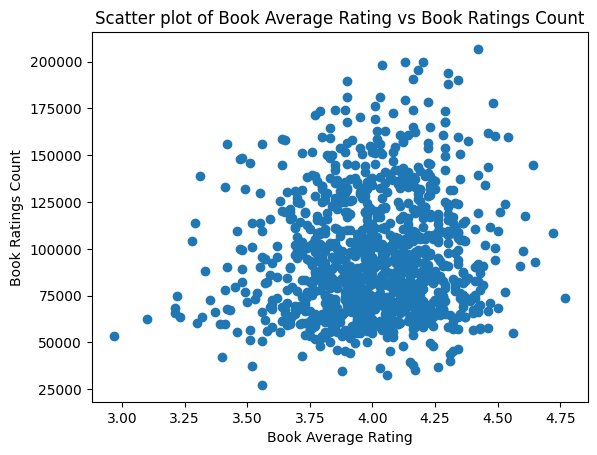

In [34]:
plt.scatter(df["Book_average_rating"], df["Book_ratings_count"])
plt.xlabel("Book Average Rating")
plt.ylabel("Book Ratings Count")
plt.title("Scatter plot of Book Average Rating vs Book Ratings Count")
plt.show()

### Preparing Total Gross Sales by Author
The code groups the dataset by author and adds together the `gross sales` values for each author. This creates total gross sales per author.


In [35]:
total_gross_sales_by_author = df.groupby("Author")["gross sales"].sum()


### Top 10 Authors by Total Gross Sales
**What the graph shows:** The bar chart displays the ten authors with the highest summed gross sales in the dataset.

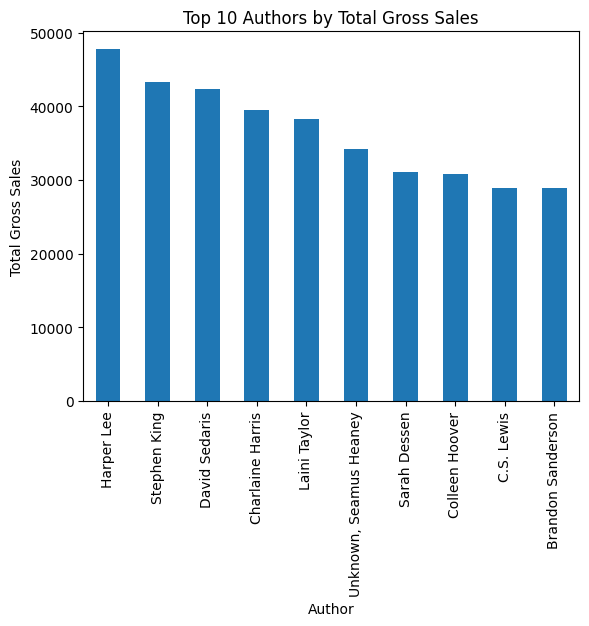

In [36]:
total_gross_sales_by_author.sort_values(ascending=False).head(10).plot(kind="bar")
plt.xlabel("Author")
plt.ylabel("Total Gross Sales")
plt.title("Top 10 Authors by Total Gross Sales")
plt.show()

### Units Sold by Author Rating
**What the graph shows:** The box plot compares the distribution of units sold across the `Author_Rating` categories.

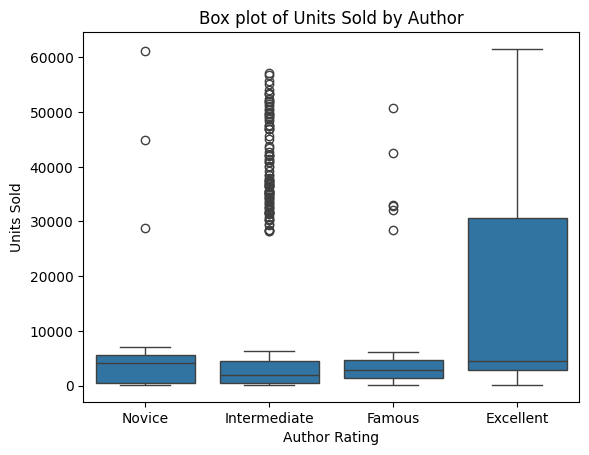

In [37]:
sns.boxplot(x="Author_Rating", y="units sold", data=df)
plt.xlabel("Author Rating")
plt.ylabel("Units Sold")
plt.title("Box plot of Units Sold by Author")
plt.show()

### Total Units Sold over the Years
**What the graph shows:** The line chart adds up units sold for books grouped by publishing year. Each point represents the total units sold for books published in that year.

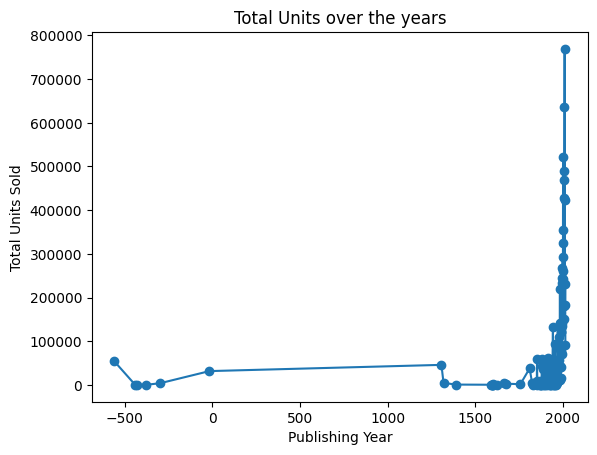

In [38]:
df.groupby("Publishing Year")["units sold"].sum().plot(kind="line", marker="o")
plt.xlabel("Publishing Year")
plt.ylabel("Total Units Sold")
plt.title("Total Units over the years")
plt.show()

### 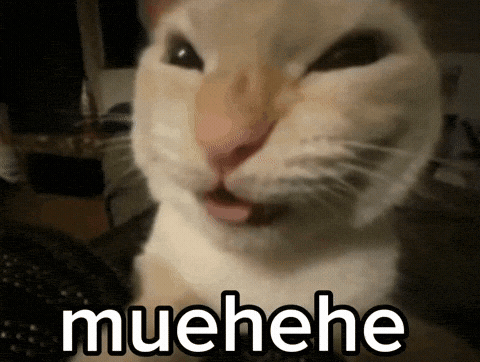